# Connect environmental observations to bounded One Health questions

**Learning question:** What can real surface observations and tract denominators support, and which One Health evidence is still missing?

Eleven complete source lessons join real Fresno Landsat samples and Census tracts while keeping environmental proxies, population denominators and health evidence distinct.

This introductory calculation is an original **synthetic** teaching exercise. Full source lessons and their actual data status are separately described below.


## Predict before running

One Health connects people, animals, plants and their environment. Global Health adds equity and missing voices; spatial epidemiology adds support, time and ecological inference. Fresno Landsat 9 data were acquired on 2024-08-30, while tract populations reference 2020-04-01. Surface temperature is neither air temperature nor personal exposure, and a vegetation/water proxy is not illness evidence.


In [1]:
from IPython.display import SVG, display
from html import escape

def svg(body, title, description, width=760, height=330):
    label = escape(title, quote=True)
    display(SVG(f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" role="img" aria-label="{label}"><title>{escape(title)}</title><desc>{escape(description)}</desc><rect width="100%" height="100%" fill="#f5f5ef" rx="12"/>{body}</svg>'))

def bars(values, title, unit):
    print(title + ' | ' + unit + ':', {k:round(v,3) for k,v in values.items()})
    n = len(values)
    height = max(250, 82 + n*36)
    maximum = max(max(values.values()), 1)
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18" fill="#123c45">{escape(title)}</text>'
    for i,(key,value) in enumerate(values.items()):
        y=58+i*36
        body += f'<text x="22" y="{y+17}" font-family="sans-serif" font-size="13">{escape(str(key))}</text><rect x="205" y="{y}" width="{max(0,value)/maximum*440:.2f}" height="23" rx="3" fill="#16756b"/><text x="{213+max(0,value)/maximum*440:.2f}" y="{y+17}" font-family="sans-serif" font-size="13">{value:.2f}</text>'
    body += f'<text x="205" y="{height-15}" font-family="sans-serif" font-size="12">zero baseline · {escape(unit)}</text>'
    svg(body, title, 'Values are printed as a text alternative; consult the chart title for data status.', height=height)

def grid(values, columns, title):
    print(title + ':', [round(v,3) for v in values])
    maximum = max(max(values),1)
    size = 54
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text>'
    for i,v in enumerate(values):
        x=25+(i%columns)*size; y=52+(i//columns)*size
        light=92-50*v/maximum
        body += f'<rect x="{x}" y="{y}" width="50" height="50" fill="hsl(169,45%,{light:.1f}%)" stroke="#123c45"/><text x="{x+25}" y="{y+29}" text-anchor="middle" font-family="sans-serif" font-size="14" fill="#061c21">{v:.1f}</text>'
    svg(body,title,'Synthetic grid with values printed in each cell; no actual boundaries.',height=max(220,70+((len(values)+columns-1)//columns)*size))

def lines(series, title, xunit, yunit):
    print(title + ':', {k:[round(v,3) for v in vs] for k,vs in series.items()})
    maximum=max(max(vs) for vs in series.values()) or 1
    body=f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text><path d="M55 55V265H710" fill="none" stroke="#123c45"/>'
    for j,(name,vs) in enumerate(series.items()):
        color=['#16756b','#a34712','#41449c'][j%3]
        pts=' '.join(f'{55+i*650/max(1,len(vs)-1):.1f},{265-v*200/maximum:.1f}' for i,v in enumerate(vs))
        body+=f'<polyline points="{pts}" fill="none" stroke="{color}" stroke-width="3"/><text x="{60+j*220}" y="310" font-family="sans-serif" font-size="13" fill="{color}">{escape(name)}</text>'
    body+=f'<text x="55" y="288" font-family="sans-serif" font-size="12">{escape(xunit)} → · {escape(yunit)} ↑ · y starts at zero</text>'
    svg(body,title,'Synthetic series; printed values are the text alternative.')


Synthetic whole-tract count: 1000 Synthetic overlap estimate: 320.0
Synthetic denominator support | people: {'whole tracts': 1000, 'uniform area-fraction estimate': 320.0}


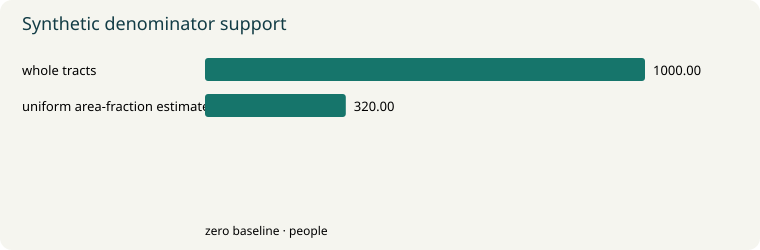

In [2]:
tracts = [{'population':400,'overlap':0.5}, {'population':600,'overlap':0.2}]
whole = sum(t['population'] for t in tracts)
area_fraction = sum(t['population']*t['overlap'] for t in tracts)
print('Synthetic whole-tract count:', whole, 'Synthetic overlap estimate:', area_fraction)
bars({'whole tracts':whole,'uniform area-fraction estimate':area_fraction}, 'Synthetic denominator support', 'people')


## Interpret the result

A whole-tract population sum is not the population inside a bounding box. An area-fraction estimate assumes uniform population within each tract. The real source profile includes 6,890 systematic Landsat samples and 166 Census tracts (764,468 whole-tract people); those totals retain their distinct measurement support and dates.

## Change one thing

Change one overlap fraction, then list the additional observations needed for a health or equity question. Follow source lessons 00–10 for provenance, QA/scaling, vegetation/water, heat, scale, point-in-polygon joins, evidence gaps and an exportable evidence brief.


## Source course and scientific boundaries

All lesson calculation inputs are bundled at data/manifest.json, data/pixels.csv and data/tracts.geojson, with source-metadata.json and README. Matplotlib is required; first browser package/runtime retrieval may use the network. Landsat DN reflectance scaling is DN×0.0000275−0.2; temperature in °C is DN×0.00341802+149−273.15, with the source QA/mask rules retained. Thermal product grid spacing is not independent thermal support.

[Complete local course guide](../../courses/onehealth/index.ipynb) · [Notebook library](../../notebook-library.ipynb)


## Sources, attribution and limits

[Reviewed source README](https://github.com/jltobias/JupyterLite-OneHealth/blob/bee8d844b22a37e65e3e34da3e922ebd8451874c/README.md) · [Source repository](https://github.com/jltobias/JupyterLite-OneHealth)

Real public-domain USGS/NASA Landsat and U.S. Census inputs retain their exact source metadata. Original OneHealth source material is included at the owner request without a general license inferred. Agency articles, photographs, presentation figures and videos remain external. Environmental proxies are not validated disease or vulnerability scores. The live explorer has separate service/CORS/acquisition requirements.

- [Read source Book](https://jltobias.github.io/JupyterLite-OneHealth/book/) — HTTP 200 - entry only
- [Open source Lab](https://jltobias.github.io/JupyterLite-OneHealth/lite/lab/index.html) — HTTP 200 - entry only
- [Open source explorer](https://jltobias.github.io/JupyterLite-OneHealth/explorer/profile/) — HTTP 200 - entry only

[Central references](../../references.ipynb)


## Explore the real-data map studio

The original small synthetic exercise above remains a method introduction. Open the [real 2D map](https://jltobias.github.io/JupyterLite-Learning-Atlas/teach/?view=2d), [3D data columns](https://jltobias.github.io/JupyterLite-Learning-Atlas/teach/?view=3d-map), or [actual coastal terrain scene](https://jltobias.github.io/JupyterLite-Learning-Atlas/teach/?view=3d-scene), then inspect its source, units, dates and missingness. The [map gallery](https://jltobias.github.io/JupyterLite-Learning-Atlas/teach/#map-library) includes reviewed source experiences with explicit data classifications.

The studio reuses the real source-course inputs. Terrain screens count sampled MSL-referenced heights; population columns are people per native cell; Fresno values are satellite proxies/whole-tract Census totals; the historical poster counts retain their reporting scope. Tide-gauge window anomalies remain separate from terrain. These views do not reconstruct private facilities or calculate new flood risk. [Methods and complete citations](https://jltobias.github.io/JupyterLite-Learning-Atlas/book/references.html#real-data-maps-and-scenes-2026-11-13).


## Browser GIS pathway

**Geographic question:** What do real sampled surfaces and tract denominators support?

**Data readiness (B):** QA/scaling lesson, tract join, 6,890 sampled pixels, 166 tract features, manifest, and exact source metadata.

**Start from the chapter evidence:** [QA/scaling lesson](../../courses/onehealth/03_qa_scaling.ipynb) · [tract join](../../courses/onehealth/07_eo_population_joins.ipynb) · [6,890 sampled pixels](https://github.com/jltobias/JupyterLite-Learning-Atlas/blob/main/content/courses/onehealth/data/pixels.csv) (`courses/onehealth/data/pixels.csv`) · [166 tract features](https://github.com/jltobias/JupyterLite-Learning-Atlas/blob/main/content/courses/onehealth/data/tracts.geojson) (`courses/onehealth/data/tracts.geojson`) · [manifest](https://github.com/jltobias/JupyterLite-Learning-Atlas/blob/main/content/courses/onehealth/data/manifest.json) (`courses/onehealth/data/manifest.json`) · [exact source metadata](https://github.com/jltobias/JupyterLite-Learning-Atlas/blob/main/content/courses/onehealth/data/source-metadata.json) (`courses/onehealth/data/source-metadata.json`)

- **[RustGIS Web](https://web.rustgis.app/):** Use actual pixels/tracts/manifest/source metadata; export bounded points or existing GEOID summary with QA/time/units/sample counts. In RustGIS, import the reviewed geographic export through Add Data; inspect the selected feature IDs and attribute table before styling.
- **[GeoLibre Web](https://web.geolibre.app/):** Use actual pixels/tracts/manifest/source metadata; export bounded points or existing GEOID summary with QA/time/units/sample counts. In GeoLibre, import that same reviewed file, compare a second legend/filter, and reconcile its count and one known attribute with the notebook.

**Handoff:** Use the [GIS workbench](../../gis-workbench.ipynb) to validate/export an attributed WGS84 layer. Download the GeoJSON, method record and review prompt from `exports/`, then import through the chosen app’s file picker. Compare `_atlas_source_id` (or source `GEOID`) with the original IDs; app-generated internal IDs may differ. Return changed results by explicit upload. Apps and the notebook share no files or kernel state. Practice-only Census data remain Fresno 2020, never this subject’s observations.

**Optional AI prompt (approved subject evidence only):** “Find the unsupported step from environmental proxy to disease/vulnerability. Cite supplied feature IDs/fields, separate observations from assumptions, abstain when evidence is missing, and propose one falsifiable check.” For the common practice package, use its generated schema/summary prompt instead. A human-written answer completes the same task.

**GeoAI opportunity:** Held-out prediction needs health/animal/community labels; proxy mapping alone is not inference. Any later fitted exercise must name target/features and spatial/temporal support, reserve a spatial/temporal holdout, inspect leakage and uncertainty, and state evidence that would disprove the interpretation. Styling, thresholds, schema checks and chat alone are not model fitting.

**Human evidence check:** Surface C differs from air; 300m display differs from 30m footprint; 2024 samples/2020 population distinct. Ask the intended reader which decision the map supports; change one legend, filter or annotation, then recheck interpretation against the same IDs and values.

**Continue:** [cross-tool guide and optional Ollama setup](../../browser-gis.ipynb) · [RustGIS assistance](../../courses/rustgis/07_ollama_assistance.ipynb) · [GeoLibre setup](../../courses/geolibre-geoai/18_ollama_geolibre_setup.ipynb) · [chat-to-map](../../courses/geolibre-geoai/19_ollama_chat_to_map.ipynb) · [evidence review](../../courses/geolibre-geoai/20_ollama_evidence_review.ipynb). AI is optional; no service or model is called by this pathway.
